**08 · Recuperación y `reconstrucción` desde el embedding**

**Advertencia conceptual:** con el descriptor global actual **no existe una reconstrucción exacta e inversa** del objeto. Lo que sí puede hacerse de forma defendible es: (i) recuperar el objeto más cercano en el espacio embebido, (ii) inspeccionar los vecinos del embedding y (iii) construir una `reconstrucción por recuperación` o un prototipo aproximado a partir de vecinos. Este cuaderno documenta precisamente esa idea.

In [1]:
from pathlib import Path
import sys, subprocess, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'benchmarks'/'common.py').exists() and (p/'pyproject.toml').exists()), None)
if ROOT is None:
    raise RuntimeError("Abre Jupyter desde la raíz de point-field o una subcarpeta del repositorio.")
sys.path.insert(0, str(ROOT/'benchmarks'))
OUT = ROOT/'runs'/'tesis_figuras'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'figure.dpi': 120, 'savefig.dpi': 300, 'pdf.fonttype': 42})
COLORS = ['#21618c','#c65036','#63933e','#8b65a5','#c49a38','#458e91','#d16c9f','#555555']
def save(fig, name):
    for ext in ('pdf','png'):
        fig.savefig(OUT/f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)
def points(ax, X, y=None, s=6):
    X=np.asarray(X)
    if y is None:
        if X.shape[1]==2: ax.scatter(X[:,0],X[:,1],s=s,c=COLORS[0],linewidths=0)
        else: ax.scatter(X[:,0],X[:,1],X[:,2],s=s,c=COLORS[0],linewidths=0)
    else:
        labs=np.unique(y)
        for j,c in enumerate(labs):
            col='#b9b9b9' if c==-1 else COLORS[j%len(COLORS)]
            m=(y==c)
            if X.shape[1]==2: ax.scatter(X[m,0],X[m,1],s=s,c=col,linewidths=0)
            else: ax.scatter(X[m,0],X[m,1],X[m,2],s=s,c=col,linewidths=0)
    ax.set_xticks([]); ax.set_yticks([])
    if X.shape[1]==2:
        ax.set_aspect('equal', adjustable='box')
    else:
        ax.set_zticks([]); ax.set_box_aspect((1,1,1)); ax.view_init(elev=23, azim=35)
def run_script(name, *args):
    subprocess.run([sys.executable, str(ROOT/'benchmarks'/name), *map(str,args)], cwd=ROOT, check=True)
print('Repositorio:', ROOT, 'Salidas:', OUT)
try:
    commit=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip()
except Exception:
    commit='No disponible'
print('Commit:', commit)


Repositorio: /home/icantu24/Documents/PEF-CD/point-field Salidas: /home/icantu24/Documents/PEF-CD/point-field/runs/tesis_figuras
Commit: 88445aa61ca2a66afcc53a931cf0927232ef232f


**1. Datos y descriptores.** El ejemplo usa familias sintéticas porque allí sí existe un control de forma razonable. En ModelNet también se puede ejecutar si ya tienes preparado el cargador de mallas.

In [3]:
from pointfield.objects import make_object_dataset
from pointfield.learning import CDDescriptor, moment_descriptor, BlockScaler
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
try:
    import umap
    HAVE_UMAP=True
except Exception:
    HAVE_UMAP=False

clouds, y, families = make_object_dataset(dim=3, n_per_class=20, n_points=512, seed=0)
cd = CDDescriptor()
F = np.array([cd(x) for x in clouds])
S = BlockScaler(cd.block_slices(3)).fit_transform(F)
embedder = umap.UMAP(n_neighbors=15, min_dist=0.15, random_state=0) if HAVE_UMAP else PCA(n_components=2)
Z = embedder.fit_transform(S)
D = pairwise_distances(S)
np.fill_diagonal(D, np.inf)
clouds = np.stack(clouds, axis=0)
print('Clouds:', clouds.shape, 'Descriptor:', S.shape, 'Embedding:', Z.shape, 'UMAP:', HAVE_UMAP)


Clouds: (140, 512, 3) Descriptor: (140, 78) Embedding: (140, 2) UMAP: False


**2. Embedding y vecinos.** La primera figura muestra el embedding. La segunda toma consultas concretas y muestra sus vecinos más próximos en el espacio del descriptor; esto es la forma más honesta de `invertir` el embedding con el modelo actual.

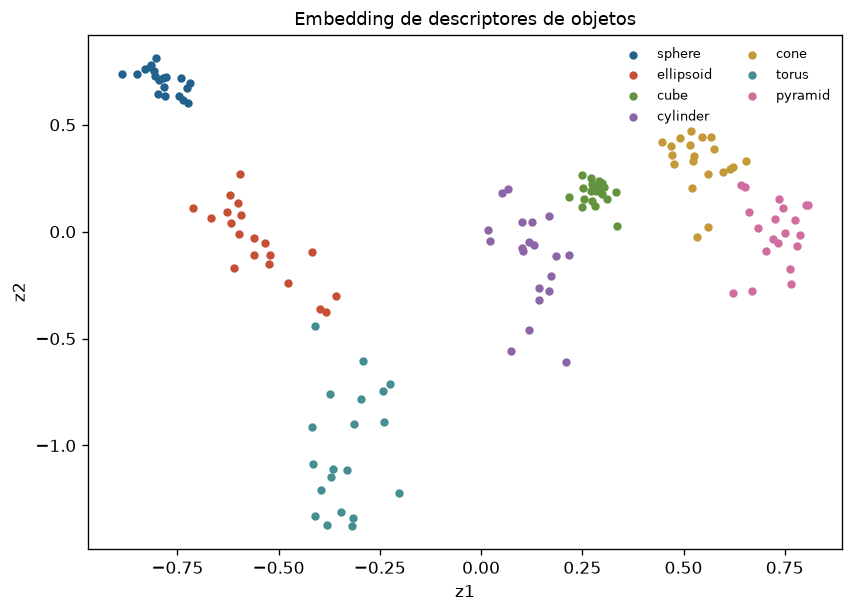

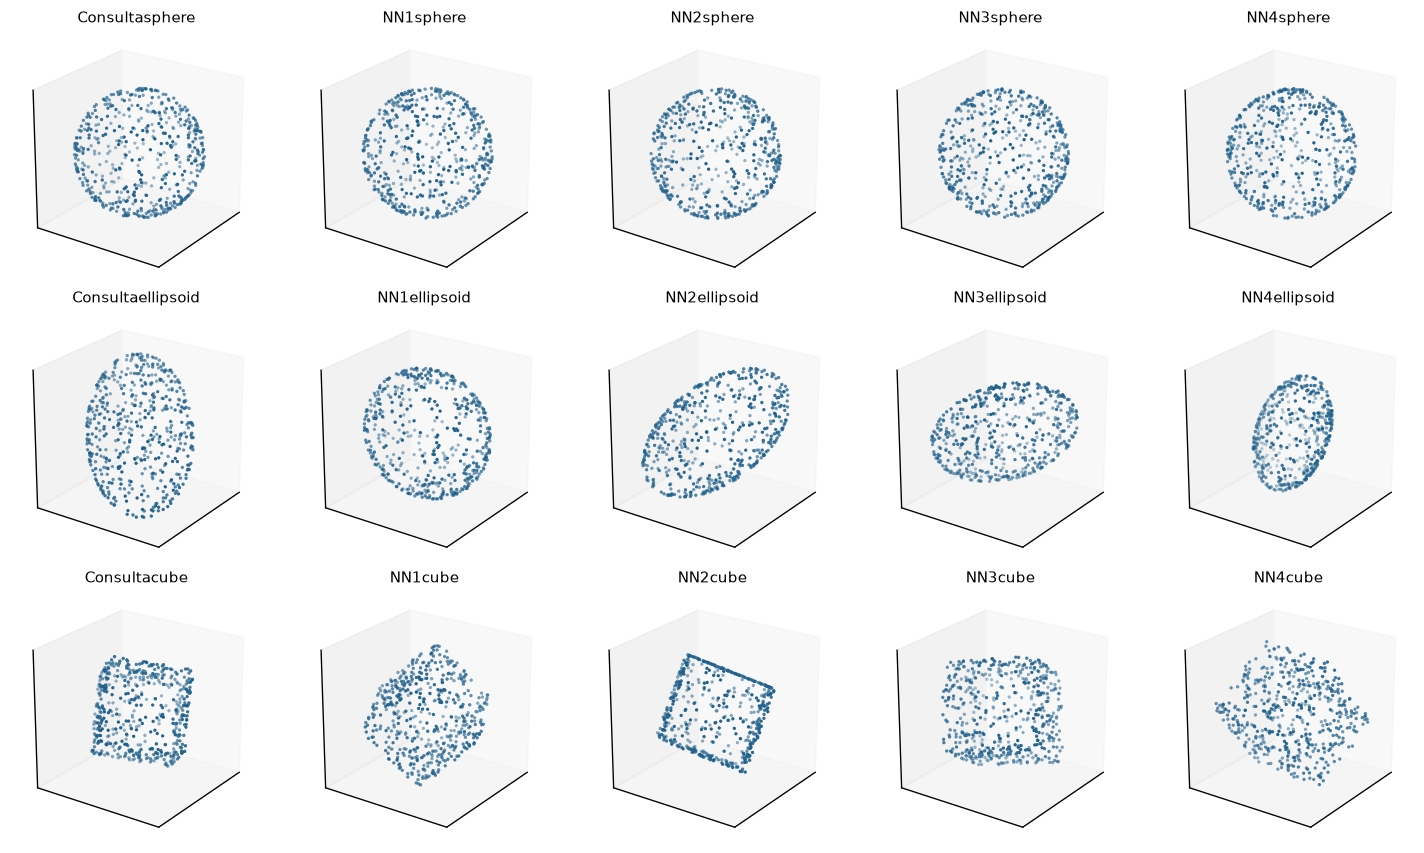

In [5]:
fig,ax=plt.subplots(figsize=(7,5), constrained_layout=True)
for j,c in enumerate(np.unique(y)):
    m=(y==c)
    ax.scatter(Z[m,0], Z[m,1], s=16, label=str(families[int(c)]), c=COLORS[j%len(COLORS)])
ax.set(title='Embedding de descriptores de objetos', xlabel='z1', ylabel='z2')
ax.legend(fontsize=8, frameon=False, ncol=2)
save(fig,'08_embedding_objetos')

queries=[np.flatnonzero(y==c)[0] for c in np.unique(y)[:3]]
K=4
fig=plt.figure(figsize=(12,7), constrained_layout=True)
for i,q in enumerate(queries):
    neigh=np.argsort(D[q])[:K]
    idxs=[q,*neigh]
    for j,idx in enumerate(idxs):
        ax=fig.add_subplot(len(queries), K+1, i*(K+1)+j+1, projection='3d')
        points(ax, clouds[idx], s=4)
        title=('Consulta' if j==0 else f'NN{j}') + f"{families[int(y[idx])]}"
        ax.set_title(title, fontsize=9)
save(fig,'08_vecinos_recuperacion')


**3. Prototipo aproximado desde vecinos.** Aquí se ofrecen dos salidas útiles para la tesis: (a) `reconstrucción por recuperación` = el vecino más cercano; (b) `prototipo local` = nube promedio de los vecinos **solo si existe correspondencia razonable**. En general, para nubes sin correspondencia este promedio es exploratorio y no debe presentarse como reconstrucción exacta.

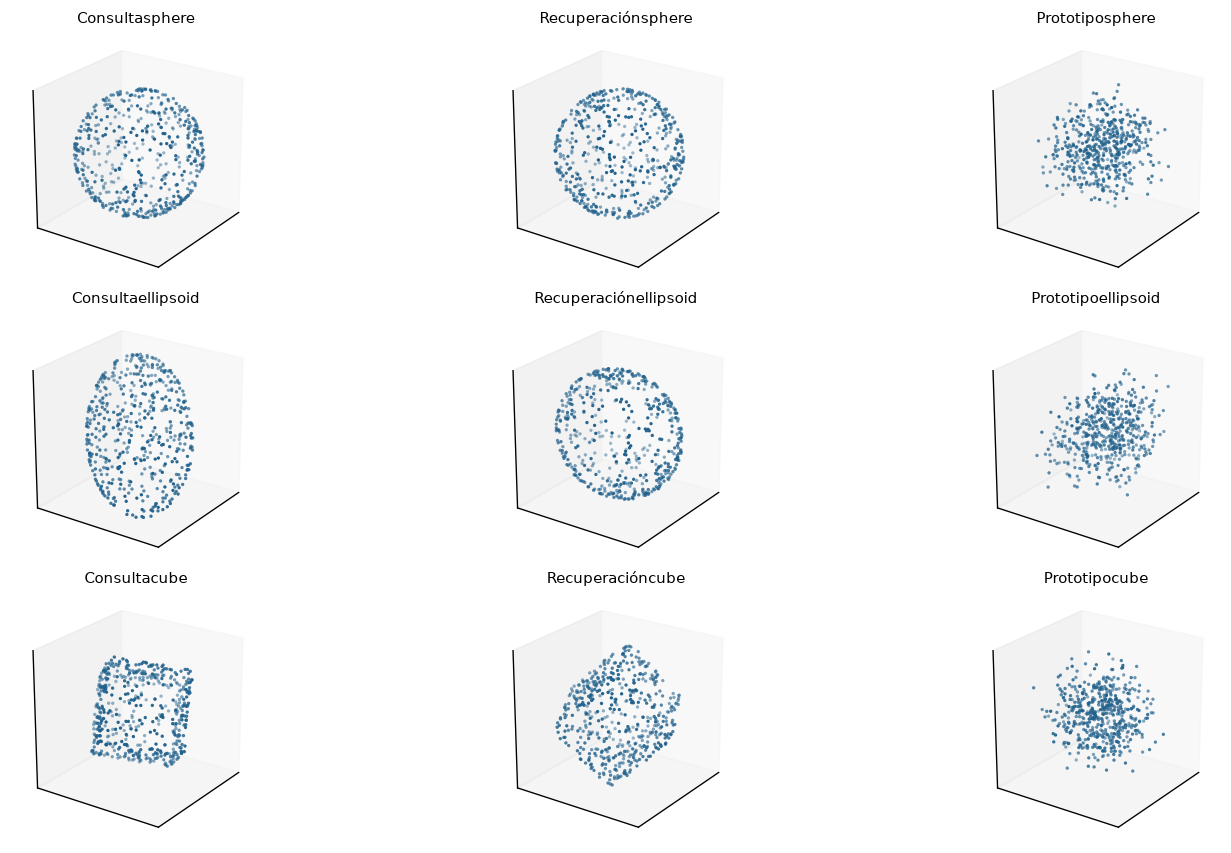

,family,Chamfer(recuperación),Chamfer(prototipo)
0,sphere,165.677126,37.957720
1,ellipsoid,5.449810,48.814029
2,cube,119.029932,39.700067


In [7]:
from sklearn.neighbors import NearestNeighbors

def chamfer(a,b):
    nn=NearestNeighbors(n_neighbors=1).fit(b)
    d1,_=nn.kneighbors(a)
    nn=NearestNeighbors(n_neighbors=1).fit(a)
    d2,_=nn.kneighbors(b)
    return float((d1**2).mean() + (d2**2).mean())

rows=[]
fig=plt.figure(figsize=(12,7), constrained_layout=True)
for i,q in enumerate(queries):
    neigh=np.argsort(D[q])[:K]
    proto=clouds[neigh].mean(axis=0)  # exploratorio: presupone nubes normalizadas con tamaño igual
    retr=clouds[neigh[0]]
    for j,(name,obj) in enumerate([('Consulta',clouds[q]),('Recuperación',retr),('Prototipo',proto)]):
        ax=fig.add_subplot(len(queries),3,i*3+j+1,projection='3d'); points(ax,obj,s=4)
        ax.set_title(f'{name}{families[int(y[q])]}', fontsize=9)
    rows.append({'family':str(families[int(y[q])]), 'Chamfer(recuperación)':chamfer(clouds[q], retr), 'Chamfer(prototipo)':chamfer(clouds[q], proto)})
save(fig,'08_reconstruccion_por_recuperacion')
score=pd.DataFrame(rows)
display(score)
score.to_csv(OUT/'08_reconstruccion_scores.csv', index=False)


**4. Opción para ModelNet.** Si ya tienes un cargador de ModelNet en point-field, sustituye `make_object_dataset` por las nubes reales y repite exactamente la misma lógica. La interpretación sigue siendo la misma: recuperación o prototipo local, no inversión exacta del descriptor.

In [8]:
print('Siguiente paso opcional: sustituir el dataset sintético por ModelNet10/40 y guardar figuras separadas por clase.')


Siguiente paso opcional: sustituir el dataset sintético por ModelNet10/40 y guardar figuras separadas por clase.
